# Lab A12 Functional Programming
**CS 3035 · Fall 2026 · Week 12 · 10 points total**  
**Name:** _Enter your name_  
**Submission:** `labA12_Lastname_Firstname.ipynb`

Complete three exercises:

| Exercise | Topic | Points |
|---|---|---:|
| LabA12.1 | Variance using Option and flatMap | 4 |
| LabA12.2 | Merge two sorted functional lists in ascending order | 3 |
| LabA12.3 | Control merge order with a lambda | 3 |
| **Total** | | **10** |

Select a Kotlin kernel. Complete each TODO, run the tests, and add the requested explanations. Restart the kernel, run all cells in order, and save actual outputs before submitting. No external library or API is required.

LabA12.1 uses Kotlin's standard `kotlin.collections.List<Double>`. LabA12.2 and LabA12.3 use our custom immutable `List`, `Nil`, and `Cons`. The variance signatures are fully qualified so the two types can coexist in this notebook.


## LabA12.1 Variance with Option and flatMap

**4 points: implementation (2), executed tests (1), explanation (1)**

### The calculation

For a nonempty list of n values, let m be its mean. The **population variance** is:

$$
m = (x1 + x2 + ... + xn) / n
$$
$$
variance = ((x1 - m)^2 + (x2 - m)^2 + ... + (xn - m)^2) / n
$$

It is important to note that a single value has variance 0.0. For an empty list, mean and variance are undefined; return `None`, not `Some(0.0)`.

For example, `[1.0, 2.0, 3.0]` has mean 2.0 and squared deviations `[1.0, 0.0, 1.0]`. Its variance is 2.0 / 3.0.



### Option utilities

`Some(value)` represents an available result. `None` represents absence. The `get` property belongs to `Some`; it is not an operation for safely extracting a value from any Option.


In [ ]:
import kotlin.math.abs
import kotlin.math.pow

sealed class Option<out A>
data class Some<out A>(val get: A) : Option<A>()
object None : Option<Nothing>()

fun <A, B> Option<A>.map(f: (A) -> B): Option<B> =
    when (this) {
        is Some -> Some(f(get))
        is None -> None
        else -> error("Unexpected Option subtype")
    }

fun <A, B> Option<A>.flatMap(f: (A) -> Option<B>): Option<B> =
    when (this) {
        is Some -> f(get)
        is None -> None
        else -> error("Unexpected Option subtype")
    }

fun mean(xs: kotlin.collections.List<Double>): Option<Double> =
    if (xs.isEmpty()) None else Some(xs.sum() / xs.size)

// Display helper for consistent output; do not change the supplied None type.
fun <A> Option<A>.show(): String =
    when (this) {
        is Some -> "Some($get)"
        is None -> "None"
        else -> error("Unexpected Option subtype")
    }


### Predict and inspect

Before running the next cell, predict each result. Fill in the table and compare your predictions with the actual output.

| Expression                         | Your prediction |
| ---------------------------------- | --------------- |
| `mean(emptyList())`                | _Answer_        |
| `mean(listOf(5.0))`                | _Answer_        |
| `mean(listOf(1.0, 2.0, 3.0))`      | _Answer_        |
| `Some(3).map { it * 2 }`           | _Answer_        |
| `Some(3).flatMap { Some(it * 2) }` | _Answer_        |

The final check verifies that `flatMap` does not call its callback when the input is `None`. If it did, the test's `error` call would fail the cell.


In [ ]:
println(mean(emptyList()).show())
println(mean(listOf(5.0)).show())
println(mean(listOf(1.0, 2.0, 3.0)).show())
println(Some(3).map { it * 2 }.show())
println(Some(3).flatMap { Some(it * 2) }.show())



### Implement variance

Complete the function below. Keep the signature and use an expression body.

Requirements:

1. Call the supplied `mean(xs)` to obtain the first mean.
2. Use **Option.flatMap** to continue only when that mean exists.
3. Inside the callback, use **List.map** to produce each squared deviation `(x - m).pow(2)` (or `(x - m) * (x - m)`).
4. Call the supplied `mean` on the squared deviations.
5. Return `Option<Double>` directly. Do not unwrap `Some` manually, cast, use `!!`, throw for an empty input, or substitute a sentinel number.
6. Use no loops, `var`, mutable collections, input, or printing in `variance`. Leave the input list unchanged.

`List.map` transforms every list element. `Option.flatMap` chains a computation whose result is already optional. The methods have different receivers and different roles.



In [ ]:
fun variance(xs: kotlin.collections.List<Double>): Option<Double> =
    TODO("Compose mean, Option.flatMap, List.map, and mean")


### Test the variance function

Run all provided checks. The supplied helper compares Double results with a tolerance of 1e-9; exact floating-point equality is not appropriate for every fraction. It throws only to report a failed test. Exceptions in test assertions do not change the required behavior of `variance`.

| Input                                      | Expected result                    |
| ------------------------------------------ | ---------------------------------- |
| Empty list                                 | `None`                             |
| `[5.0]`                                    | `Some(0.0)`                        |
| `[4.0, 4.0, 4.0]`                          | `Some(0.0)`                        |
| `[1.0, 2.0, 3.0]`                          | approximately `Some(0.6666666667)` |
| `[1.0, 2.0, 3.0, 4.0, 5.0]`                | `Some(2.0)`                        |
| `[2.0, 4.0, 4.0, 4.0, 5.0, 5.0, 7.0, 9.0]` | `Some(4.0)`                        |


In [ ]:
## Test here

## LabA12.2 Merge two sorted functional lists
**3 points: implementation and functional style (2), tests and explanation (1)**

Given two functional linked lists of integers already sorted in ascending order, return a functional list containing every element from both inputs in ascending order. Preserve duplicate values.

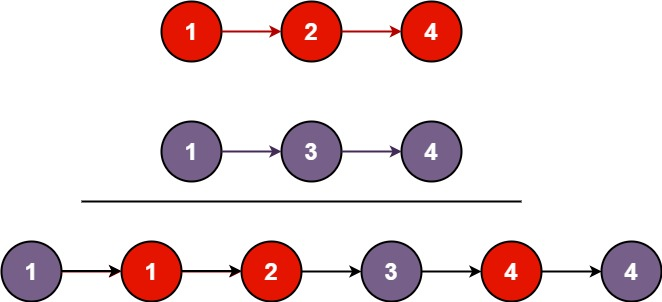

The illustration shows the value order for the merge-two-sorted-lists problem. In our immutable version, create new `Cons` nodes as needed and share a remaining suffix; do not change existing links. The colors identify the original lists, but this exercise does not require the identical node identities or tie ordering pictured. When equal heads are compared, select from list1 first.

```text
[1, 2, 4] and [1, 3, 4] → [1, 1, 2, 3, 4, 4]
[] and []                → []
[] and [0]               → [0]
```

Use only the custom functional list supplied below. Do not use the standard Kotlin List, `listOf`, arrays, built-in sorting, or conversions to implement the merge. The supplied factory uses an array internally; leave that utility unchanged.


### Supplied functional linked list

These are the course's existing list definitions. Run this cell once before implementing the merge functions. `List.of(...)` builds our custom functional list. `listOf(...)` builds Kotlin's standard list and belongs only to the variance exercise here. The definitions and direct recursive algorithms are intended for classroom-sized inputs.


In [ ]:
sealed class List<out A> {
    companion object {
        fun <A> of(vararg aa: A): List<A> {
            if (aa.isEmpty()) return Nil
            val tail = aa.sliceArray(1 until aa.size)
            return Cons(aa[0], of(*tail))
        }
    }
}

object Nil : List<Nothing>()
data class Cons<out A>(val head: A, val tail: List<A>) : List<A>()

fun <A> List<A>.tail(): List<A> =
    when (this) {
        is Cons -> this.tail
        is Nil -> throw IllegalStateException("Nil cannot have a tail")
        else -> error("Unexpected List subtype")
    }

fun <A, B> List<A>.foldRight(z: B, f: (A, B) -> B): B =
    when (this) {
        is Cons -> f(head, tail.foldRight(z, f))
        is Nil -> z
        else -> error("Unexpected List subtype")
    }

fun <A> List<A>.length(): Int = foldRight(0) { _, acc -> 1 + acc }


### Implement the ascending merge

- Use recursive `when` expressions over Nil and Cons.
- When one input is empty, return the other input directly.
- When both are nonempty, select the smaller head; select from list1 on a tie.
- Preserve all elements and duplicate values, and leave both input lists unchanged.
- Do not use loops, `var`, mutable collections, printing, or sorting inside the function.
- Tail recursion is not required.

Only the list whose head is selected advances to its tail. Complete this version before adding the lambda version in LabA12.3.


In [ ]:
fun mergeSorted(list1: List<Int>, list2: List<Int>): List<Int> =
    TODO("Recursively merge the two ascending functional lists")


In [ ]:
val ascendingFirst = List.of(1, 2, 4)
val ascendingSecond = List.of(1, 3, 4)
val ascendingMerged = mergeSorted(ascendingFirst, ascendingSecond)

## check(mergeSorted(Nil, Nil) === Nil)
## check(mergeSorted(Nil, List.of(0)) == List.of(0))
## check(mergeSorted(Nil, ascendingFirst) === ascendingFirst)
## check(mergeSorted(ascendingFirst, Nil) === ascendingFirst)
## check(mergeSorted(List.of(-3, 1, 1), List.of(-2, 1, 5)) == List.of(-3, -2, 1, 1, 1, 5))



## LabA12.3 Merge in either direction with a lambda
**3 points: higher-order implementation (2), tests and explanation (1)**

Add a second version of `mergeSorted` with a function parameter. Keep the two-argument version from LabA12.2. Kotlin distinguishes these overloads by their parameters.

`comesBeforeOrEqual(a, b)` returns true when a should appear before b or tie with b in the chosen order. Use `{ a, b -> a <= b }` for ascending order and `{ a, b -> a >= b }` for descending order.

**Both input lists must already be sorted according to the lambda.** Descending merge requires descending inputs. The lambda does not sort or reverse an input list.

Replace the fixed head comparison with a call to the lambda, and pass the same lambda to each recursive call. Use one implementation for both directions. Do not sort, reverse, hard-code a direction, or call the ascending merge and reverse its result. Keep the functional-style and structural-sharing requirements from LabA12.2.


In [ ]:
fun mergeSorted(
    list1: List<Int>,
    list2: List<Int>,
    comesBeforeOrEqual: (Int, Int) -> Boolean
): List<Int> =
    TODO("Use the supplied lambda to choose which head comes next")


In [ ]:
## Test here 

## Submission and grading

Submit one **`labA12_Lastname_Firstname.ipynb`** containing all three exercises. Complete the predictions and explanations, replace all three TODOs, and preserve the supplied checks. Restart the Kotlin kernel, run all cells from top to bottom, and save the actual outputs. The embedded illustration stays with the notebook; no separate image upload is needed.

| Exercise | Criteria | Points |
|---|---|---:|
| LabA12.1 | Variance using mean, Option.flatMap, and list mapping (2); executed checks (1); predictions and explanation of optional results (1) | 4 |
| LabA12.2 | Correct ascending recursive merge with no mutation and suffix sharing (2); executed checks and trace/explanation (1) | 3 |
| LabA12.3 | Correct lambda-controlled merge in both directions using the functional list (2); executed checks and explanation of ordering/preconditions (1) | 3 |
| **Entire lab** | | **10** |
